In [1191]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as mpe
import numpy as np
import panel as pn
from matplotlib.ticker import FuncFormatter, MaxNLocator
from panel.template import MaterialTemplate


In [1192]:
# Cargar los datos
df = pd.read_csv("ventas.csv", parse_dates=["fecha"], encoding="latin-1")

# Ver las primeras filas
df.head()

,fecha,producto,categoria,cantidad,precio_unitario,total_venta,ciudad
0,2023-01-01,Laptop,Electrónica,2,1200,2400,Buenos Aires
1,2023-01-01,Mouse,Accesorios,5,25,125,Córdoba
2,2023-01-02,Teclado,Accesorios,3,75,225,Córdoba
3,2023-01-02,Monitor,Electrónica,1,300,300,Buenos Aires
4,2023-01-03,Laptop,Electrónica,1,1200,1200,Rosario


In [1193]:
# Reviso el tipo de dato de la columna fecha y su contenido
df["fecha"].head()


0   2023-01-01
1   2023-01-01
2   2023-01-02
3   2023-01-02
4   2023-01-03
Name: fecha, dtype: datetime64[ns]

In [1194]:
# verifico la estructura del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fecha            50 non-null     datetime64[ns]
 1   producto         50 non-null     object        
 2   categoria        50 non-null     object        
 3   cantidad         50 non-null     int64         
 4   precio_unitario  50 non-null     int64         
 5   total_venta      50 non-null     int64         
 6   ciudad           50 non-null     object        
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 2.9+ KB


In [1195]:
# Convertir columnas object a category, no es necesario hacerlo en un muestreo tan chico, pero en un dataset grande puede ahorrar memoria y acelerar operaciones
categorical_cols = ["producto", "categoria", "ciudad"]

for col in categorical_cols:
    df[col] = df[col].astype("category")

# Verificamos los cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fecha            50 non-null     datetime64[ns]
 1   producto         50 non-null     category      
 2   categoria        50 non-null     category      
 3   cantidad         50 non-null     int64         
 4   precio_unitario  50 non-null     int64         
 5   total_venta      50 non-null     int64         
 6   ciudad           50 non-null     category      
dtypes: category(3), datetime64[ns](1), int64(3)
memory usage: 2.7 KB


In [1196]:
# resumen estadístico de las columnas numéricas
df.describe()


,fecha,cantidad,precio_unitario,total_venta
count,50,50.00000,50.000000,50.000000
mean,2023-03-04 00:00:00,5.80000,419.700000,1377.320000
min,2023-01-01 00:00:00,1.00000,24.000000,125.000000
25%,2023-02-02 00:00:00,3.00000,50.500000,370.000000
50%,2023-03-03 00:00:00,4.50000,215.000000,782.500000
75%,2023-04-04 00:00:00,8.00000,970.000000,1300.000000
max,2023-05-05 00:00:00,16.00000,1200.000000,5950.000000
std,NaN,4.17964,470.515403,1546.003517


Cantidad de filas (count): 
                50.
Promedio (mean):
                Cantidad: 5.8 unidades por venta.
                Precio unitario: 419.7
                Total venta: 1377.32
Rangos (min, max):
                Cantidad: desde 1 hasta 16 unidades.
                Precio unitario: desde 24 hasta 1200.
                Total venta: desde 125 hasta 5950.
Percentiles (25%, 50%, 75%): 
                Dan la distribución de los datos, útil para detectar outliers. 
                Por ejemplo, el 75% de las ventas tienen un total menor a 1300.
Std: 
                la desviación estándar indica que hay bastante dispersión, sobre todo en precio unitario y total venta, lo que sugiere que hay ventas muy altas comparadas con la mayoría.

In [1197]:
# Ver las primeras filas nuevamente para confirmar que todo está en orden
df.head()


,fecha,producto,categoria,cantidad,precio_unitario,total_venta,ciudad
0,2023-01-01,Laptop,Electrónica,2,1200,2400,Buenos Aires
1,2023-01-01,Mouse,Accesorios,5,25,125,Córdoba
2,2023-01-02,Teclado,Accesorios,3,75,225,Córdoba
3,2023-01-02,Monitor,Electrónica,1,300,300,Buenos Aires
4,2023-01-03,Laptop,Electrónica,1,1200,1200,Rosario


In [1198]:
# Analizamos las ventas por diferentes dimensiones
df["producto"].value_counts().head(10)   # Top 10 productos más vendidos


producto
Laptop         13
Auriculares     8
Mouse           8
Monitor         6
Teclado         6
Smartwatch      5
Tablet          4
Name: count, dtype: int64

In [1199]:
df["categoria"].value_counts()           # Ventas por categoría

categoria
Electrónica    23
Accesorios     22
Wearables       5
Name: count, dtype: int64

In [1200]:
# San Miguel De Tucumán -> Tucumán
df['ciudad'] = df['ciudad'].replace('San Miguel de Tucumán', 'Tucumán')
# Unificar 'Wearables' a 'Indumentaria Tech'
df['categoria'] = df['categoria'].cat.rename_categories({'Wearables': 'Indumentaria Tech'})

C:\Users\Usuario\AppData\Local\Temp\ipykernel_8128\1831873022.py:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df['ciudad'] = df['ciudad'].replace('San Miguel de Tucumán', 'Tucumán')


In [1201]:
# Reviso si hay valores nulos en el DataFrame
df.isnull().sum()


fecha              0
producto           0
categoria          0
cantidad           0
precio_unitario    0
total_venta        0
ciudad             0
dtype: int64

In [1202]:
# Definir la función de formato para el eje Y
def format_k(num, pos):
    """
    Función para formatear los números del "eje y" a miles (K).
    """
    if abs(num) >= 1000:
        return f'{num/1000:.0f}k'
    return f'{num:.0f}'

In [1203]:
#Habilitamos Panel
pn.extension(template='material', raw_css=["""
/* Scrollbar más visible para los MultiSelect con clase .scroll-visible */
.scroll-visible select{
  scrollbar-width: auto;                 /* Firefox */
  scrollbar-color: #8a8a8a #f1f1f1;
}
.scroll-visible select::-webkit-scrollbar{
  width: 12px;                           /* Chrome/Edge/Safari */
}
.scroll-visible select::-webkit-scrollbar-track{
  background: #f1f1f1;
  border-radius: 8px;
}
.scroll-visible select::-webkit-scrollbar-thumb{
  background: #8a8a8a;
  border-radius: 8px;
  border: 2px solid #f1f1f1;
}
.scroll-visible select::-webkit-scrollbar-thumb:hover{
  background: #5a5a5a;
}
"""])

In [1204]:
def create_monthly_sales_chart(df, mes_inicial, mes_final):
    """
    Crea un gráfico de ventas mensuales, filtrado por un rango de meses seleccionados.
    """
    inicio_rango = pd.to_datetime(mes_inicial)
    fin_rango = pd.to_datetime(mes_final) + pd.offsets.MonthEnd(0)
    
    df_filtrado = df[(df['fecha'] >= inicio_rango) & (df['fecha'] <= fin_rango)].copy()
    
    if df_filtrado.empty:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.set_title("No hay datos para esta selección", fontsize=16)
        ax.axis('off')
        plt.close(fig)
        return fig
    
    ventas_por_mes = df_filtrado.groupby(pd.Grouper(key='fecha', freq='ME'))['total_venta'].sum()
    
    # Formatear los meses
    meses = ventas_por_mes.index.strftime('%b %Y')
    
    base_color = '#4682B4'
    accent_color = '#00bcd4'
    
    sizes = ventas_por_mes.values / ventas_por_mes.values.max() * 500 if ventas_por_mes.values.max() > 0 else np.zeros_like(ventas_por_mes.values)
    
    colores_burbujas = [base_color] * len(ventas_por_mes)
    if len(ventas_por_mes) > 0 and ventas_por_mes.values.max() > 0:
        indice_max = np.argmax(ventas_por_mes.values)
        colores_burbujas[indice_max] = accent_color
    
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(meses, ventas_por_mes.values, s=sizes, c=colores_burbujas, alpha=0.8, edgecolor='black')
    ax.plot(meses, ventas_por_mes.values, color=base_color, linestyle='-', alpha=0.6)
    
    def format_k(num, pos):
        return f'{num/1000:.0f}k' if abs(num) >= 1000 else f'{num:.0f}'
    
    # Etiquetas arriba de cada burbuja con offset dinámico y halo blanco
    for x, y, s in zip(meses, ventas_por_mes.values, sizes):
        color_texto = accent_color if y == ventas_por_mes.values.max() else 'black'

        offset_pts = 6 + np.sqrt(s) * 0.6   # offset dinámico (más grande → más separación)

        txt = ax.annotate(
            f'{y:.0f}',
            xy=(x, y),
            xytext=(0, offset_pts),         # separación vertical en puntos
            textcoords='offset points',
            ha='center', va='bottom',
            fontsize=10, fontweight='bold',
            color=color_texto,
            clip_on=False
        )
        # Halo blanco para mejorar legibilidad
        txt.set_path_effects([
            mpe.withStroke(linewidth=3, foreground="white")
        ])
    
    if not ventas_por_mes.empty:
        max_y = ventas_por_mes.values.max()
        ax.set_ylim(0, max_y * 1.25)   # margen extra arriba
    
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5)) 
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))
    
    ax.set_title(f"Ventas mensuales ({inicio_rango.strftime('%b %Y')} - {fin_rango.strftime('%b %Y')})", fontsize=16, fontweight='bold')
    ax.set_xlabel('Mes', fontsize=12)
    ax.set_ylabel('Total venta', fontsize=12)
    ax.tick_params(axis='x')
    ax.grid(axis='y', alpha=0.3)
    
    plt.close(fig)
    return fig


In [1205]:
def create_city_sales_chart(df, ciudades_seleccionadas):
    """
    Crea un gráfico de barras que compara las ventas de las ciudades seleccionadas.
    Esta funcion maneja 1, 2 o multiples ciudades.
    """
    if not ciudades_seleccionadas:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.set_title("Selecciona al menos una ciudad", fontsize=16)
        ax.axis('off')
        plt.close(fig)
        return fig

    # --- Lógica de título simplificada ---
    if len(ciudades_seleccionadas) == 1:
        # Si se selecciona una sola ciudad, muestra su nombre
        titulo = f"Total de Ventas - {ciudades_seleccionadas[0]}"
    elif len(ciudades_seleccionadas) == 2:
        # Si se seleccionan dos ciudades, usa el formato "vs."
        titulo = f"Total de Ventas {ciudades_seleccionadas[0]} vs {ciudades_seleccionadas[1]}"
    else:
        # Si se seleccionan más de dos ciudades, muestra un título genérico
        titulo = "Total de Ventas - Ciudades Seleccionadas"
        
    df_filtrado = df[df['ciudad'].isin(ciudades_seleccionadas)].copy()
    
    ventas_por_ciudad = df_filtrado.groupby('ciudad', observed=True)['total_venta'].sum().sort_values(ascending=False)
    
    base_color = '#4682B4'
    accent_color = '#00bcd4'
    
    colores_barras = [accent_color if ciudad == ventas_por_ciudad.index[0] else base_color for ciudad in ventas_por_ciudad.index]

    def format_k(num, pos):
        return f'{num/1000:.0f}k' if abs(num) >= 1000 else f'{num:.0f}'
    
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(ventas_por_ciudad.index, ventas_por_ciudad.values, color=colores_barras, alpha=0.8)
    
    for i, valor in enumerate(ventas_por_ciudad.values):
        ax.text(i, valor + (ventas_por_ciudad.values.max() * 0.01 if ventas_por_ciudad.values.max() > 0 else 0), f'{valor:.0f}', 
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')
        
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))    
    ax.set_title(titulo, fontsize=16, fontweight='bold')
    ax.set_xlabel('Ciudad', fontsize=12)
    ax.set_ylabel('Total venta', fontsize=12)
    ax.tick_params(axis='x')
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    
    plt.close(fig)
    return fig

In [1206]:
def create_category_sales_chart(df):
    """
    Gráfico de barras de ventas por categoría con buenas separaciones.
    """
    ventas_por_categoria = (df.groupby('categoria', observed=True)['total_venta']
                              .sum()
                              .sort_values(ascending=False))

    base_color = '#4682B4'
    accent_color = '#00bcd4'
    colores_barras = [accent_color if i == 0 else base_color
                      for i in range(len(ventas_por_categoria))]

    # Más compacto y con auto-ajuste de layout
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)

    bars = ax.bar(ventas_por_categoria.index,
                  ventas_por_categoria.values,
                  color=colores_barras, alpha=0.8)

    # Formato miles
    def format_k(num, pos):
        return f'{num/1000:.0f}k' if abs(num) >= 1000 else f'{num:.0f}'
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))

    # Etiquetas arriba con halo y offset en puntos
    ymax = ventas_por_categoria.values.max() if len(ventas_por_categoria) else 0
    for bar, valor in zip(bars, ventas_por_categoria.values):
        txt = ax.annotate(f'{valor:.0f}',
                          xy=(bar.get_x() + bar.get_width()/2, valor),
                          xytext=(0, 8),            # separación vertical en puntos
                          textcoords='offset points',
                          ha='center', va='bottom',
                          fontsize=9, fontweight='bold',
                          color='black',
                          clip_on=False)
        txt.set_path_effects([mpe.withStroke(linewidth=2, foreground="white")])

    # Margen extra arriba para que no se corte el número
    if ymax > 0:
        ax.set_ylim(0, ymax * 1.15)

    # Evitar solape con los ticks del eje X
    ax.set_xlabel('Categoría', fontsize=12, labelpad=12)  # más separación con los ticks
    ax.set_ylabel('Total venta', fontsize=12)
    ax.tick_params(axis='x')                 # leve rotación ayuda con nombres largos
    ax.grid(axis='y', alpha=0.3, linestyle='--')

    ax.set_title('Ventas por categoría', fontsize=16, fontweight='bold')

    return fig

Launching server at http://localhost:52420


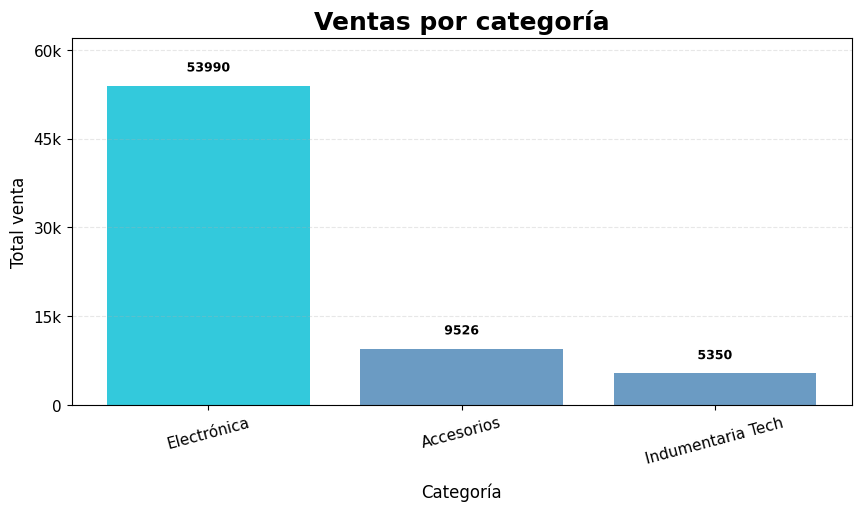

In [ ]:
# --- Construir el Dashboard con Panel ---

# ========= Helper responsive (según ancho en px del contenedor) =========
def responsive_cfg(container_width):
    w = container_width or 1200
    if w < 520:      # móvil
        return dict(figsize=(5.0, 3.2), fs_title=14, fs_label=10, fs_tick=9, xtick_rot=15, labelpad=10)
    elif w < 900:    # tablet
        return dict(figsize=(7.0, 4.2), fs_title=16, fs_label=12, fs_tick=10, xtick_rot=15, labelpad=10)
    else:            # desktop
        return dict(figsize=(8.5, 5.0), fs_title=18, fs_label=12, fs_tick=11, xtick_rot=15, labelpad=12)

def _apply_fig_cfg(fig, cfg):
    try:
        fig.set_size_inches(*cfg['figsize'], forward=True)
    except Exception:
        pass
    for ax in getattr(fig, "axes", []):
        try: ax.title.set_fontsize(cfg['fs_title'])
        except Exception: pass
        try:
            ax.xaxis.label.set_fontsize(cfg['fs_label'])
            ax.yaxis.label.set_fontsize(cfg['fs_label'])
            ax.xaxis.labelpad = cfg['labelpad']
        except Exception: pass
        try:
            ax.tick_params(axis='x', labelsize=cfg['fs_tick'])
            ax.tick_params(axis='y', labelsize=cfg['fs_tick'])
            for t in ax.get_xticklabels(): t.set_rotation(cfg['xtick_rot'])
        except Exception: pass
    return fig

# ========= Widgets =========
ciudades_unicas   = sorted(df['ciudad'].unique().tolist())
fechas_por_mes    = sorted(df['fecha'].dt.strftime('%Y-%m').unique().tolist())
categorias_unicas = sorted(df['categoria'].unique().tolist())

filas_visibles_ciudades   = len(ciudades_unicas)
filas_visibles_categorias = len(categorias_unicas)

# Ventas por Ciudad
filtro_modo_ciudad = pn.widgets.RadioBoxGroup(
    name='Modo de Visualización',
    options=['Ver todas las ciudades', 'Comparar dos ciudades'],
    value='Ver todas las ciudades'
)
filtro_todas_ciudades = pn.widgets.MultiSelect(
    name='Seleccionar Ciudades',
    options=ciudades_unicas,
    value=ciudades_unicas,
    sizing_mode='stretch_width',
    size=filas_visibles_ciudades,
    css_classes=['scroll-visible']
)
filtro_ciudad1 = pn.widgets.Select(name='Ciudad 1', options=ciudades_unicas, value=ciudades_unicas[0])
filtro_ciudad2 = pn.widgets.Select(name='Ciudad 2', options=ciudades_unicas, value=ciudades_unicas[1])

# Ventas Mensuales
filtro_mes_inicial = pn.widgets.Select(name='Mes Inicial', options=fechas_por_mes, value=fechas_por_mes[0])
filtro_mes_final   = pn.widgets.Select(name='Mes Final',   options=fechas_por_mes, value=fechas_por_mes[-1])

# Ventas por Categoría (rango meses + ciudades + categorías)
filtro_cat_mes_inicial = pn.widgets.Select(name='Mes Inicial', options=fechas_por_mes, value=fechas_por_mes[0])
filtro_cat_mes_final   = pn.widgets.Select(name='Mes Final',   options=fechas_por_mes, value=fechas_por_mes[-1])
filtro_cat_ciudades    = pn.widgets.MultiSelect(
    name="Ciudades - Mantener Ctrl para múltiples",
    options=ciudades_unicas,
    value=ciudades_unicas,
    sizing_mode='stretch_width',
    size=filas_visibles_ciudades,
    css_classes=['scroll-visible']
)
filtro_cat_categorias  = pn.widgets.MultiSelect(
    name="Categorías - Mantener Ctrl para múltiples",
    options=categorias_unicas,
    value=categorias_unicas,
    sizing_mode='stretch_width',
    size=filas_visibles_categorias,
    css_classes=['scroll-visible']
)

# ========= Ancho reactivo (anchor invisible) =========
width_anchor = pn.Spacer(sizing_mode='stretch_width', height=0)

# ========= Callbacks / Gráficos =========
@pn.depends(filtro_modo_ciudad, filtro_todas_ciudades, filtro_ciudad1, filtro_ciudad2, width_anchor.param.width)
def generar_grafico_ciudad(modo, ciudades_todas, ciudad1, ciudad2, w):
    cfg = responsive_cfg(w)
    ciudades_a_graficar = ciudades_todas if modo == 'Ver todas las ciudades' else [ciudad1, ciudad2]
    try:
        fig = create_city_sales_chart(df, ciudades_a_graficar, **cfg)
    except TypeError:
        fig = create_city_sales_chart(df, ciudades_a_graficar)
        fig = _apply_fig_cfg(fig, cfg)
    return pn.pane.Matplotlib(fig, tight=True, sizing_mode='stretch_width')

def _mensual_resp(w, mi, mf):
    cfg = responsive_cfg(w)
    try:
        fig = create_monthly_sales_chart(df=df, mes_inicial=mi, mes_final=mf, **cfg)
    except TypeError:
        fig = create_monthly_sales_chart(df=df, mes_inicial=mi, mes_final=mf)
        fig = _apply_fig_cfg(fig, cfg)
    return pn.pane.Matplotlib(fig, tight=True, sizing_mode='stretch_width')

grafico_interactivo_mensual = pn.bind(
    _mensual_resp,
    width_anchor.param.width, filtro_mes_inicial, filtro_mes_final
)

def _filtrar_df(df_base, mes_ini, mes_fin, ciudades_sel, categorias_sel):
    ini = pd.to_datetime(mes_ini)
    fin = pd.to_datetime(mes_fin) + pd.offsets.MonthEnd(0)
    mask = (
        (df_base['fecha'] >= ini) & (df_base['fecha'] <= fin) &
        (df_base['ciudad'].isin(ciudades_sel)) &
        (df_base['categoria'].isin(categorias_sel))
    )
    return df_base.loc[mask].copy()

@pn.depends(filtro_cat_mes_inicial, filtro_cat_mes_final, filtro_cat_ciudades, filtro_cat_categorias, width_anchor.param.width)
def generar_grafico_categoria(m_ini, m_fin, ciudades_sel, categorias_sel, w):
    cfg = responsive_cfg(w)
    df_filtrado = _filtrar_df(df, m_ini, m_fin, ciudades_sel, categorias_sel)

    if df_filtrado.empty:
        fig, ax = plt.subplots(figsize=cfg['figsize'])
        ax.set_title("Sin datos para los filtros seleccionados", fontsize=cfg['fs_title'])
        ax.axis('off')
        plt.close(fig)
        return pn.pane.Matplotlib(fig, tight=True, sizing_mode='stretch_width')

    try:
        fig = create_category_sales_chart(df_filtrado, **cfg)
    except TypeError:
        fig = create_category_sales_chart(df_filtrado)
        fig = _apply_fig_cfg(fig, cfg)
    return pn.pane.Matplotlib(fig, tight=True, sizing_mode='stretch_width')

# ========= Tabs =========
tabs = pn.Tabs(
    ("Ventas Mensuales", grafico_interactivo_mensual),
    ("Ventas por Ciudad", generar_grafico_ciudad),
    ("Ventas por Categoría", generar_grafico_categoria),
    tabs_location='above'
)

# ========= Sidebar dinámico =========
def _bloque_filtros_ciudad():
    col_todas = pn.Column(
        pn.pane.Markdown("### Ventas por Ciudad"),
        filtro_modo_ciudad,
        pn.Spacer(height=5),
        pn.pane.Markdown("**Seleccionar Ciudades**"),
        filtro_todas_ciudades
    )
    col_comparar = pn.Column(
        pn.pane.Markdown("### Ventas por Ciudad"),
        filtro_modo_ciudad,
        pn.Spacer(height=5),
        pn.Row(filtro_ciudad1),
        pn.Row(filtro_ciudad2)
    )
    return pn.bind(lambda modo: col_todas if modo == 'Ver todas las ciudades' else col_comparar,
                   filtro_modo_ciudad)

def sidebar_contenido(active_tab_index):
    # 0 = Mensuales, 1 = Ciudad, 2 = Categoría
    if active_tab_index == 0:
        return pn.Column(
            pn.pane.Markdown("### Ventas Mensuales"),
            pn.Row(filtro_mes_inicial),
            pn.Row(filtro_mes_final),
        )
    elif active_tab_index == 1:
        return _bloque_filtros_ciudad()
    else:
        return pn.Column(
            pn.pane.Markdown("### Ventas por Categoría"),
            pn.pane.Markdown("**Rango de meses**"),
            pn.Row(filtro_cat_mes_inicial),
            pn.Row(filtro_cat_mes_final),
            pn.pane.Markdown("**Ciudades**"),
            filtro_cat_ciudades,
            pn.pane.Markdown("**Categorías**"),
            filtro_cat_categorias
        )

sidebar_dinamico = pn.bind(sidebar_contenido, active_tab_index=tabs.param.active)

# ========= Template =========
template = MaterialTemplate(
    site="Análisis de Ventas",
    title="Dashboard de Ventas de la Empresa",
    sidebar=[sidebar_dinamico],
    main=[width_anchor, tabs]  # Anchor primero para tomar el ancho disponible
)

template.servable()